# 03 · Strategy: adaptive model selection (ATOMS) with purged validation

Notebook 02 showed that 1-second closes do not reflect real price moves (43% of seconds show no change, and moves spread over several consecutive seconds), while volatility measured from 1-minute returns already matches the hourly figure. So the strategy works on **1-minute bars**. This notebook:

1. **Tests for stationarity**, to establish whether an adaptive method is needed at all.
2. **Detects regimes** with a two-state HMM (forward-filtered, so no look-ahead), used only to describe the market, never to trade.
3. **Runs the strategy walk-forward:** every period, three model families are trained on several window lengths, and **ATOMS** (Capponi, Huang, Sidaoui, Wang & Zou, 2026) picks one candidate using a purged validation split inside each past period. The pick is tested on the next, unseen period.
4. **Evaluates** against fixed-horizon selection, every single candidate, the zero forecast and buy-and-hold, with a Diebold–Mariano test and a bootstrap interval on the Sharpe ratio.

### What is kept out of sample

| Rule | How it is enforced |
|---|---|
| A period is forecast before its data is used for anything | The walk-forward loop trains, validates and selects using periods `< t` only, then tests on period `t` |
| Validation rows never appear in training | Within each period, validation blocks are held out, with a purge before and an embargo after each block |
| Design choices are not tuned on the reported period | Everything in the settings cell was fixed using data before `REPORT_FROM`; results are reported from that date on |
| ATOMS's own scale constant `M′` is not fitted on test data | Calibrated on the design period only, following the paper's recipe |

## Settings

In [1]:
SYMBOL = "BTCUSDT"
DATA_DIR = None                 # None = <repo>/data
HORIZON = 1                     # forecast horizon in minutes

# periods: the clock of the walk-forward. "W-SUN" = weeks; "M" = calendar months.
# Weeks give ~200 periods since 2023; months only ~47, too few for ATOMS to adapt or for any test to have power.
PERIOD = "W-SUN"
WINDOWS = [1, 4, 16, 64, 0]     # training windows in periods (0 = all history), the paper's 4^k ladder
GBT_MAX_WINDOW = 16             # boosted trees are not fitted on windows longer than this (speed)
MAX_LOOKBACK = 64               # most past periods ATOMS may look back over when comparing candidates
MIN_HISTORY = 4                 # periods of history before the first selection
FH_SHORT = 4                    # fixed-horizon benchmark: validation window in periods

# purged validation split inside each period
BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN = 360, 0.20, 60, 15
SEEDS = [0]                     # repeat the random block assignment; the paper uses 20 seeds

MODEL_SETTINGS = [
    {"kind": "enet", "alpha": 0.001, "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.01,  "l1_ratio": 0.5},
    {"kind": "enet", "alpha": 0.1,   "l1_ratio": 0.5},
    {"kind": "gbt",  "depth": 2, "lr": 0.05, "n_iter": 150, "min_leaf": 1000},
    {"kind": "gbt",  "depth": 3, "lr": 0.05, "n_iter": 150, "min_leaf": 1000},
]
ATOMS_DELTA = 0.1               # the paper's delta'

REPORT_FROM = "2024-01-01"      # design period before this date; results reported from it
RERUN = False                   # True = ignore cached walk-forward results

In [2]:
import sys, warnings, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from btc import features, splits, models, atoms, regimes, evaluate, walkforward, plotting
from btc.features import FEATURES
plotting.use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA = Path(DATA_DIR) if DATA_DIR else ROOT / "data"
PROC = DATA / "processed"; PROC.mkdir(parents=True, exist_ok=True)
REPORT_FROM = pd.Timestamp(REPORT_FROM, tz="UTC")
KIND_COLOR = {"zero": plotting.MUTED, "enet": plotting.BLUE, "gbt": plotting.ORANGE}
KIND_NAME = {"zero": "zero forecast", "enet": "elastic net", "gbt": "boosted trees"}

## 1. Features and target

All features at minute *i* use bars up to and including *i*. The target is the log return from the close of minute *i* to the close of minute *i + HORIZON*, in basis points.

| Feature | What it measures |
|---|---|
| `ret_1`, `ret_5`, `ret_15`, `ret_60` | Momentum / reversal over the last 1–60 minutes |
| `rv_15`, `rv_60` | Realised volatility over the last 15 and 60 minutes |
| `range_1` | High–low range of the last minute |
| `vol_z`, `trades_z` | Volume and trade count vs their trailing 24-hour mean, in standard deviations |
| `imb_1`, `imb_15` | Taker-buy imbalance (aggressive buying minus selling, over total), last minute and 15-minute average |
| `hour_sin`, `hour_cos` | Time of day, as a smooth cycle |

Bars built from fewer than 50 of their 60 seconds are dropped, and any feature whose window touches a gap is dropped with it.

In [3]:
m1 = pd.read_parquet(PROC / f"{SYMBOL}-1m.parquet")
F = features.build(m1, horizon=HORIZON)
print(f"{len(F):,} usable minutes from {F.index.min()} to {F.index.max()}  ({100*len(F)/len(m1):.1f}% of bars)")
F[FEATURES + ["y"]].describe().T[["mean", "std", "min", "max"]]

2,035,228 usable minutes from 2023-01-01 11:59:00+00:00 to 2026-11-14 23:58:00+00:00  (100.0% of bars)


,mean,std,min,max
ret_1,0.0000,0.0006,-0.0438,0.0311
ret_5,0.0000,0.0014,-0.0907,0.0603
ret_15,0.0000,0.0025,-0.1013,0.0684
ret_60,0.0000,0.0049,-0.1161,0.0851
rv_15,0.0020,0.0016,0.0000,0.0604
rv_60,0.0041,0.0029,0.0000,0.0681
range_1,0.0006,0.0007,0.0000,0.0657
vol_z,-0.0053,1.0469,-4.1660,7.3128
trades_z,-0.0075,1.0552,-6.0781,8.8518
imb_1,-0.0262,0.4564,-0.9985,0.9991


## 2. Is the data non-stationary?

ATOMS only earns its keep if the data changes character over time. Three checks, from the textbook one to the one that matters for prediction:

1. **Unit-root tests (ADF, KPSS)** on log prices and on returns. ADF's null is "unit root", KPSS's null is "stationary", so running both gives a two-sided picture. The expected result is the textbook one: prices have a unit root, returns do not.
2. **Rolling volatility.** Even with no unit root, the *scale* of returns can shift.
3. **Rolling feature–target correlations and rolling model coefficients.** This is the kind of non-stationarity ATOMS is built for: the *relationship* between today's information and tomorrow's return moving over time. A return series can pass ADF and still fail this.

In [4]:
from statsmodels.tsa.stattools import adfuller, kpss

daily_logp = np.log(m1["close"].resample("1D").last().dropna())
hourly_ret = np.log(m1["close"]).diff().resample("1h").sum().dropna()
rows = []
for name, x, reg in [("log price (daily)", daily_logp, "ct"), ("return (hourly)", hourly_ret, "c"), ("return (1-minute, every 10th)", F["ret_1"].iloc[::10], "c")]:
    adf_p = adfuller(x, regression=reg, autolag="AIC")[1]
    kp_p = kpss(x, regression=reg, nlags="auto")[1]
    rows.append({"series": name, "ADF p-value": adf_p, "KPSS p-value": kp_p,
                 "verdict": ("unit root" if adf_p > 0.05 else "no unit root") + ", " + ("KPSS rejects stationarity" if kp_p < 0.05 else "KPSS does not reject")})
pd.DataFrame(rows).set_index("series")

ipykernel_37348\111372325.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kp_p = kpss(x, regression=reg, nlags="auto")[1]


ipykernel_37348\111372325.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_p = kpss(x, regression=reg, nlags="auto")[1]


,ADF p-value,KPSS p-value,verdict
series,,,
log price (daily),0.8735,0.0100,"unit root, KPSS rejects stationarity"
return (hourly),0.0000,0.0224,"no unit root, KPSS rejects stationarity"
"return (1-minute, every 10th)",0.0000,0.1000,"no unit root, KPSS does not reject"


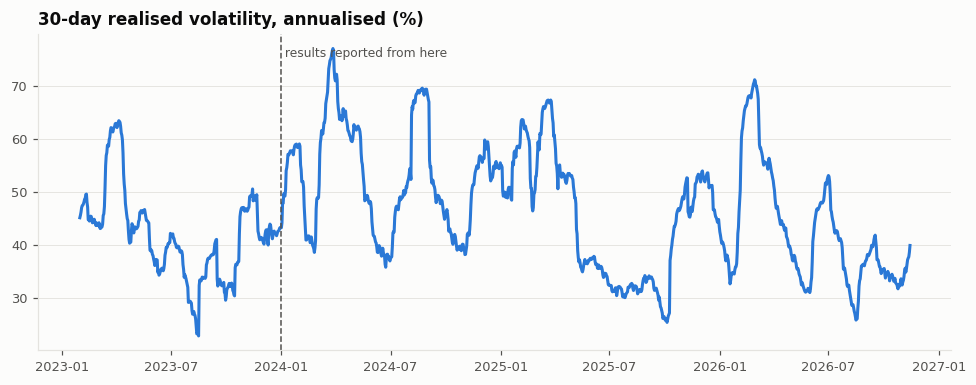

Range of 30-day volatility: 23% to 77%  (3.4x)


In [5]:
daily = pd.DataFrame({"ret": np.log(m1["close"]).diff().resample("1D").sum()})
daily["rv30"] = 100 * np.sqrt(np.log(m1["close"]).diff().pow(2).resample("1D").sum().rolling(30).mean() * 365)
fig, ax = plt.subplots()
ax.plot(daily.index, daily.rv30, color=plotting.BLUE)
ax.axvline(REPORT_FROM, color=plotting.MUTED, ls="--", lw=1); ax.text(REPORT_FROM, ax.get_ylim()[1]*0.97, " results reported from here", fontsize=8, color=plotting.MUTED, va="top")
ax.set_title("30-day realised volatility, annualised (%)"); plt.tight_layout(); plt.show()
print(f"Range of 30-day volatility: {daily.rv30.min():.0f}% to {daily.rv30.max():.0f}%  ({daily.rv30.max()/daily.rv30.min():.1f}x)")

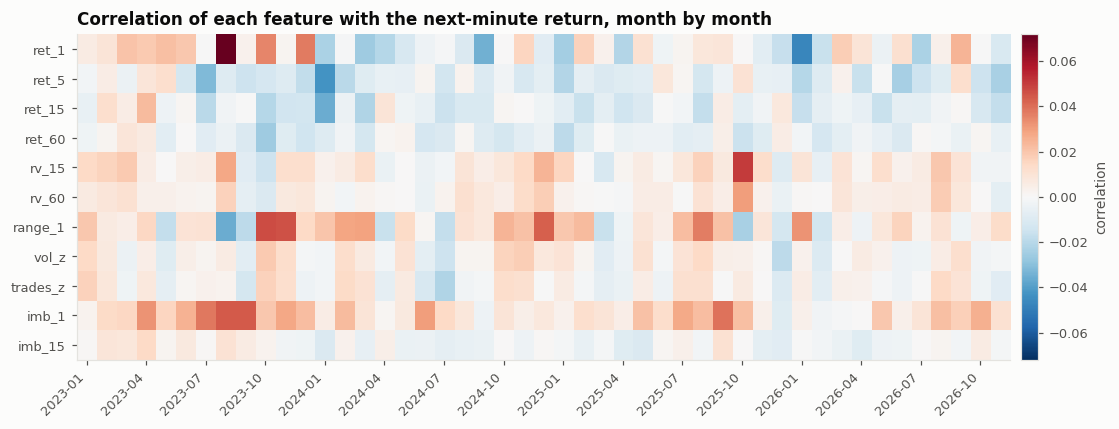

Months in which the sign of the correlation flipped:
ret_1       17
ret_5       16
ret_15      14
ret_60      16
rv_15       13
rv_60       13
range_1     20
vol_z       23
trades_z    27
imb_1        6
imb_15      17


In [6]:
# rolling (monthly) correlation of each feature with the next return
mon = F.groupby(F.index.to_period("M"))
corr = pd.DataFrame({c: mon.apply(lambda d, c=c: d[c].corr(d["y"])) for c in FEATURES if not c.startswith("hour")})
fig, ax = plt.subplots(figsize=(11, 4))
lim = np.nanmax(np.abs(corr.values))
im = ax.imshow(corr.T.values, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_yticks(range(corr.shape[1])); ax.set_yticklabels(corr.columns)
ax.set_xticks(range(0, len(corr), 3)); ax.set_xticklabels([str(p) for p in corr.index[::3]], rotation=45, ha="right"); ax.grid(False)
ax.set_title("Correlation of each feature with the next-minute return, month by month")
fig.colorbar(im, ax=ax, pad=0.01, label="correlation"); plt.tight_layout(); plt.show()
sign_flips = (np.sign(corr).diff().abs() == 2).sum()
print("Months in which the sign of the correlation flipped:"); print(sign_flips.to_string())

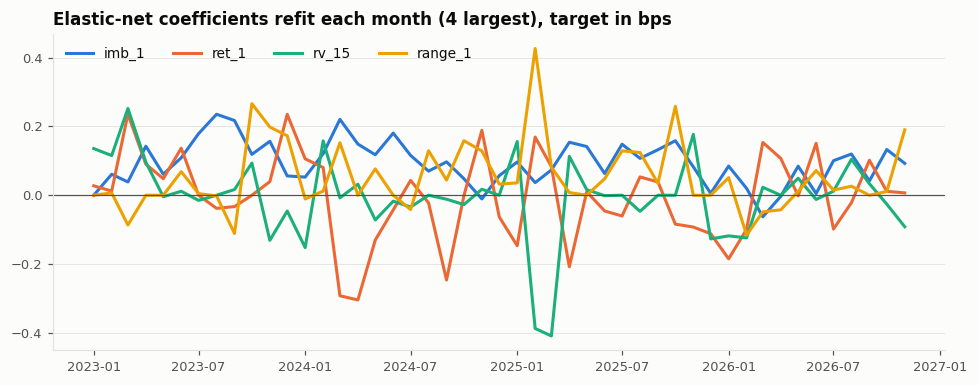

In [7]:
# rolling coefficients: one elastic net per month
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
coefs = {}
for p, d in mon:
    Xs = StandardScaler().fit_transform(d[FEATURES]); Xs = np.clip(Xs, -5, 5)
    coefs[p] = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=5000).fit(Xs, d["y"]).coef_
coefs = pd.DataFrame(coefs, index=FEATURES).T
show = coefs.abs().mean().sort_values(ascending=False).index[:4]
fig, ax = plt.subplots()
for c in show: ax.plot(coefs.index.to_timestamp(), coefs[c], label=c)
ax.axhline(0, color=plotting.MUTED, lw=0.8); ax.legend(ncol=4); ax.set_title("Elastic-net coefficients refit each month (4 largest), target in bps")
plt.tight_layout(); plt.show()

**Reading these three charts:** if volatility swings several-fold, correlations change sign across months and coefficients wander rather than hover around a stable value, then a model fitted on one stretch of history will be mis-calibrated on another. That is the case for selecting the model *and* the amount of history adaptively.

## 3. Regimes (descriptive only)

A two-state Gaussian HMM is fitted on hourly returns and log realised volatility over the **design period only**. From then on its parameters are frozen and the state probability is computed with a **forward filter**: the probability at hour *t* uses data up to hour *t*, never after. (`hmmlearn.predict_proba` would use the whole series, which looks ahead.)

The regime is used to *describe* results, for example "which model did ATOMS choose in calm vs stormy weeks". It is not a feature and not a trading signal.

State means (hourly return bps, log RV):  calm +0.34, -12.46   stormy +2.12, -10.57
Expected stay in state:  calm 12 h   stormy 9 h
Share of hours in the stormy state: 52.2%


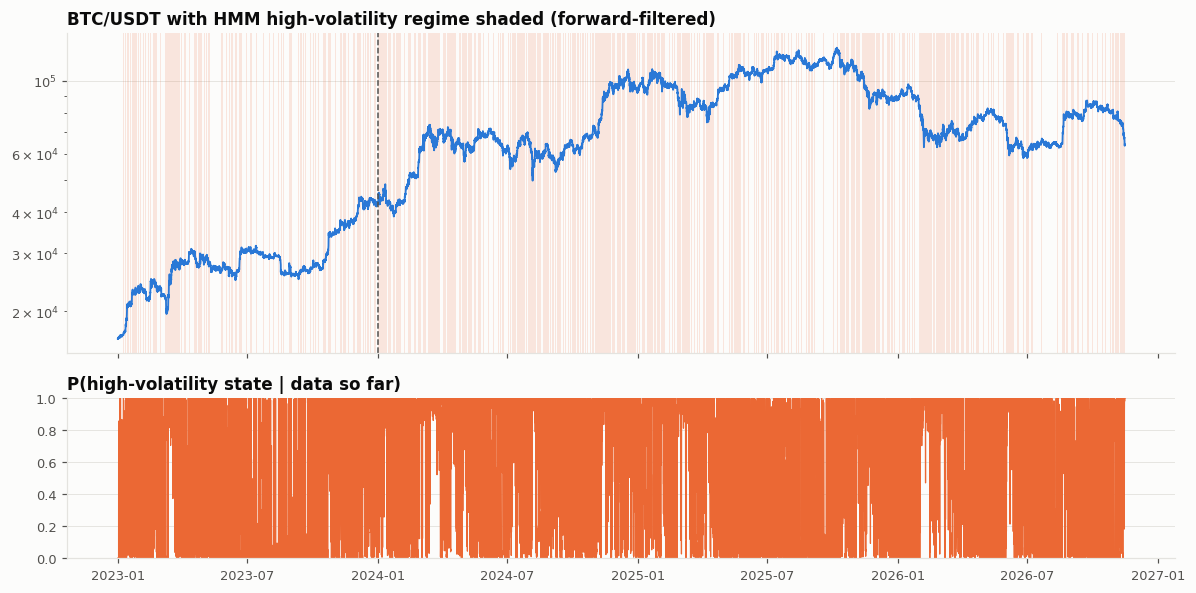

In [8]:
hx = regimes.hourly_inputs(m1)
hmm = regimes.fit_hmm(hx[hx.index < REPORT_FROM], n_states=2)
p_high = regimes.regime_series(hmm, hx)
regime = (p_high > 0.5).rename("stormy")
hi = int(np.argmax(hmm.means_[:, 1])); lo = 1 - hi
print(f"State means (hourly return bps, log RV):  calm {hmm.means_[lo][0]:+.2f}, {hmm.means_[lo][1]:.2f}   stormy {hmm.means_[hi][0]:+.2f}, {hmm.means_[hi][1]:.2f}")
print(f"Expected stay in state:  calm {1/(1-hmm.transmat_[lo,lo]):.0f} h   stormy {1/(1-hmm.transmat_[hi,hi]):.0f} h")
print(f"Share of hours in the stormy state: {100*regime.mean():.1f}%")

def shade_regimes(ax, reg=regime, color=plotting.ORANGE):
    """Shade the periods in which the filtered probability of the high-vol state exceeds 0.5."""
    r = reg.astype(int); edges = r.diff().fillna(r.iloc[0])
    starts = r.index[edges == 1]; ends = r.index[edges == -1]
    if r.iloc[-1] == 1: ends = ends.append(pd.DatetimeIndex([r.index[-1]]))
    for s, e in zip(starts, ends): ax.axvspan(s, e, color=color, alpha=0.15, lw=0)

fig, (a, b) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
px = m1["close"].resample("1h").last()
a.plot(px.index, px, color=plotting.BLUE, lw=1.2); shade_regimes(a); a.set_title("BTC/USDT with HMM high-volatility regime shaded (forward-filtered)")
a.set_yscale("log"); a.axvline(REPORT_FROM, color=plotting.MUTED, ls="--", lw=1)
b.plot(p_high.index, p_high, color=plotting.ORANGE, lw=0.8); b.set_ylim(0, 1); b.set_title("P(high-volatility state | data so far)")
plt.tight_layout(); plt.show()

## 4. The method

### Periods and the purged split

The data is cut into **periods** (`PERIOD`, weeks by default). Inside each period, 6-hour blocks are drawn at random; 20% of them become **validation**, the rest **training**. Training rows within 60 minutes before a validation block are **purged** (their forward returns or feature windows reach into the block) and rows within 15 minutes after it are **embargoed**.

```
one period (week) ──────────────────────────────────────────────────────────►
 train │ train │ purge ▌VALIDATION▐ emb │ train │ train │ purge ▌VALIDATION▐ emb │ train
```

Random *minutes* on both sides, as in the paper's 80/20 split, would let near-identical neighbours leak across. Contiguous blocks with a buffer do not.

### Candidates

A candidate is a model setting **and** a training window. Three families × windows of 1, 4, 16, 64 periods and all history (the paper's 4ᵏ ladder), plus the zero forecast:

- **zero**: forecasts 0. If nothing beats it, the strategy stays flat.
- **elastic net**: linear, three penalty strengths.
- **boosted trees**: shallow (depth 2–3), heavily regularised, on windows up to 16 periods.

### Each period *t*, in order

1. **Train** every candidate on the *training* rows of its own window (periods before *t*).
2. **Score** every candidate on the *validation* rows of the last `MAX_LOOKBACK` periods.
3. **Select** with ATOMS: a random pivot candidate is compared against every other one; the survivors go to the next round until one is left. Each pairwise comparison chooses its own look-back length by trading off *stale data* (the loss gap drifting over time) against *too little data* (noise), equations 4.4–4.7 of the paper.
4. **Test** the winner on **all** rows of period *t*, which nothing has seen. Record the forecast.
5. Move to *t + 1*.

### Benchmarks (same candidates, different selector)

- **FH-Short / FH-Long**: lowest average validation loss over the last 4 periods / all periods.
- **Every single candidate held fixed** throughout, including the zero forecast.
- **Buy-and-hold** for the strategy comparison.

In [9]:
cands = models.candidate_grid(MODEL_SETTINGS, WINDOWS, GBT_MAX_WINDOW)
print(f"{len(cands)} candidates:"); print(", ".join(c.label for c in cands))

22 candidates:
zero, enet(alpha=0.001,l1_ratio=0.5) | 1p, enet(alpha=0.001,l1_ratio=0.5) | 4p, enet(alpha=0.001,l1_ratio=0.5) | 16p, enet(alpha=0.001,l1_ratio=0.5) | 64p, enet(alpha=0.001,l1_ratio=0.5) | allp, enet(alpha=0.01,l1_ratio=0.5) | 1p, enet(alpha=0.01,l1_ratio=0.5) | 4p, enet(alpha=0.01,l1_ratio=0.5) | 16p, enet(alpha=0.01,l1_ratio=0.5) | 64p, enet(alpha=0.01,l1_ratio=0.5) | allp, enet(alpha=0.1,l1_ratio=0.5) | 1p, enet(alpha=0.1,l1_ratio=0.5) | 4p, enet(alpha=0.1,l1_ratio=0.5) | 16p, enet(alpha=0.1,l1_ratio=0.5) | 64p, enet(alpha=0.1,l1_ratio=0.5) | allp, gbt(depth=2,lr=0.05,n_iter=150,min_leaf=1000) | 1p, gbt(depth=2,lr=0.05,n_iter=150,min_leaf=1000) | 4p, gbt(depth=2,lr=0.05,n_iter=150,min_leaf=1000) | 16p, gbt(depth=3,lr=0.05,n_iter=150,min_leaf=1000) | 1p, gbt(depth=3,lr=0.05,n_iter=150,min_leaf=1000) | 4p, gbt(depth=3,lr=0.05,n_iter=150,min_leaf=1000) | 16p


### Calibrating ATOMS's scale constant

The confidence bound ψ̂ (equation 4.4) contains a constant `M′` that bounds the per-row loss gap *u* between two candidates. The paper sets it to the **90th percentile of 8·y²** over the pre-test period, rather than the theoretical maximum, and shows (Table 12) that halving or doubling it barely changes results.

That recipe assumes forecasts are on the same scale as *y*. Here they are not: minute returns have a standard deviation of a few basis points, while forecasts are fractions of a basis point, so 8·y² overstates the typical loss gap by roughly two orders of magnitude. With that value the bound never resolves and every comparison falls back to the longest look-back. So the paper's own "typical value" idea is applied to the quantity `M′` actually bounds: the 90th percentile of |u| over the look-back, computed per pair from past validation rows only (`ATOMS_M = None`). The cell shows both numbers for the record.

In [10]:
y_design = F.loc[F.index < REPORT_FROM, "y"].to_numpy()
print(f"Paper recipe, 90th percentile of 8y^2 on the design period: {np.quantile(8 * y_design ** 2, 0.9):.3g} bps^2")
ATOMS_M = None   # data-driven: 90th percentile of |u| per pair, from past validation rows

Paper recipe, 90th percentile of 8y^2 on the design period: 493 bps^2


## 5. Run the walk-forward

This is the slow cell. Each period refits every candidate; boosted trees dominate the time. On the full history with the default grid, expect a few hours per seed on a laptop; a progress line with the elapsed time prints per period, so the total is predictable after the first ten. Results are cached in `data/processed/wf_seed*.parquet`, so re-running the notebook skips this unless `RERUN = True`. One progress line prints per period.

In [11]:
runs = {}
for seed in SEEDS:
    f_sel, f_fc = PROC / f"wf_selections_seed{seed}.parquet", PROC / f"wf_forecasts_seed{seed}.parquet"
    if f_sel.exists() and f_fc.exists() and not RERUN:
        runs[seed] = {"selections": pd.read_parquet(f_sel), "forecasts": pd.read_parquet(f_fc)}
        print(f"seed {seed}: loaded cached results ({len(runs[seed]['selections'])} periods)"); continue
    frame = splits.split_all(F, PERIOD, BLOCK_MIN, VAL_FRAC, PURGE_MIN, EMBARGO_MIN, seed)
    print(f"seed {seed}: {frame.period.nunique()} periods; rows -> train {(frame.role==0).mean():.1%}, validation {(frame.role==1).mean():.1%}, purged/embargoed {(frame.role==-1).mean():.1%}")
    runs[seed] = walkforward.run(frame, cands, min_history=MIN_HISTORY, max_lookback=MAX_LOOKBACK, fh_short=FH_SHORT,
                                 atoms_delta=ATOMS_DELTA, atoms_M=ATOMS_M, seed=seed)
    runs[seed]["selections"].to_parquet(f_sel); runs[seed]["forecasts"].to_parquet(f_fc)
sel = runs[SEEDS[0]]["selections"]; fc = runs[SEEDS[0]]["forecasts"]

seed 0: loaded cached results (199 periods)


## 6. Results

Everything below uses only periods from `REPORT_FROM` onwards. Periods before that were the design and burn-in stretch.

### 6a. Forecast accuracy: out-of-sample R² against a zero forecast

As in the paper (and Gu, Kelly & Xiu 2020), R² is measured against a forecast of zero, not the historical mean. On 1-minute BTC returns, values are expected to be small fractions of a percent. The question is the ranking, and whether ATOMS tracks the best fixed choice without knowing it in advance.

In [12]:
rep = fc[fc.index >= REPORT_FROM].copy()
cand_cols = [c.label for c in cands]
if len(SEEDS) > 1:   # average forecasts across seeds for the selectors
    for k in ("atoms", "fh_short", "fh_long"):
        rep[k] = np.mean([runs[s]["forecasts"].loc[rep.index, k] for s in SEEDS], axis=0)

def r2_table(d):
    rows = {"ATOMS": d["atoms"], "FH-Short": d["fh_short"], "FH-Long": d["fh_long"]}
    rows.update({f"fixed: {c}": d[c] for c in cand_cols})
    t = pd.Series({k: 100 * evaluate.oos_r2(d["y"].to_numpy(), v.to_numpy()) for k, v in rows.items()}, name="OOS R2 (%)")
    return t

r2 = r2_table(rep)
best_fixed = r2.filter(like="fixed:").drop("fixed: zero").idxmax()
print(f"ATOMS {r2['ATOMS']:+.4f}%   FH-Short {r2['FH-Short']:+.4f}%   FH-Long {r2['FH-Long']:+.4f}%")
print(f"Best single candidate in hindsight: {best_fixed} at {r2[best_fixed]:+.4f}%")
r2.to_frame().style.format("{:+.4f}").bar(subset=["OOS R2 (%)"], align="zero", color=[plotting.ORANGE, plotting.BLUE])

ATOMS -0.0140%   FH-Short -0.0302%   FH-Long -0.0119%
Best single candidate in hindsight: fixed: enet(alpha=0.1,l1_ratio=0.5) | allp at +0.0074%


,OOS R2 (%)
ATOMS,-0.0140
FH-Short,-0.0302
FH-Long,-0.0119
fixed: zero,+0.0000
"fixed: enet(alpha=0.001,l1_ratio=0.5) | 1p",-0.3672
"fixed: enet(alpha=0.001,l1_ratio=0.5) | 4p",-0.0707
"fixed: enet(alpha=0.001,l1_ratio=0.5) | 16p",-0.0159
"fixed: enet(alpha=0.001,l1_ratio=0.5) | 64p",+0.0006
"fixed: enet(alpha=0.001,l1_ratio=0.5) | allp",+0.0009
"fixed: enet(alpha=0.01,l1_ratio=0.5) | 1p",-0.3260


In [13]:
# year by year, and calm vs stormy weeks
rep["year"] = rep.index.year
rep["stormy"] = regime.reindex(rep.index, method="ffill").fillna(False).astype(bool).values
def r2_by(group):
    return rep.groupby(group).apply(lambda d: pd.Series({k: 100 * evaluate.oos_r2(d["y"].to_numpy(), d[c].to_numpy())
                                                      for k, c in [("ATOMS", "atoms"), ("FH-Short", "fh_short"), ("FH-Long", "fh_long"), ("best fixed", best_fixed.replace("fixed: ", ""))]}))
display(r2_by("year").style.format("{:+.4f}").set_caption("OOS R2 (%) by year"))
display(r2_by("stormy").rename(index={False: "calm", True: "stormy"}).style.format("{:+.4f}").set_caption("OOS R2 (%) by HMM regime"))

,ATOMS,FH-Short,FH-Long,best fixed
year,,,,
2024,-0.0424,-0.0529,-0.0419,+0.0066
2025,+0.0121,+0.0009,+0.0152,+0.0112
2026,+0.0036,-0.0288,+0.0074,+0.0041


,ATOMS,FH-Short,FH-Long,best fixed
stormy,,,,
calm,+0.0987,+0.0857,+0.0988,+0.0438
stormy,-0.0273,-0.0439,-0.0249,+0.0031


### 6b. Is the difference real? Diebold–Mariano test

The DM test compares the squared forecast errors of two methods row by row, with a Newey–West variance to allow for serial correlation. A negative statistic means the first method is more accurate; |DM| > 1.96 is significant at 5%.

In [14]:
e_atoms = (rep["atoms"] - rep["y"]).to_numpy()
rows = []
for name, col in [("FH-Short", "fh_short"), ("FH-Long", "fh_long"), ("best fixed candidate", best_fixed.replace("fixed: ", "")), ("zero forecast", "zero")]:
    e_other = (rep[col] - rep["y"]).to_numpy()
    if np.allclose(e_atoms, e_other):
        rows.append({"ATOMS vs": name, "DM statistic": 0.0, "p-value": 1.0, "note": "identical forecasts"}); continue
    r = evaluate.diebold_mariano(e_atoms, e_other, h=HORIZON)
    rows.append({"ATOMS vs": name, "DM statistic": r["dm_stat"], "p-value": r["p_value"], "note": ""})
pd.DataFrame(rows).set_index("ATOMS vs").style.format({"DM statistic": "{:+.2f}", "p-value": "{:.3f}"})

,DM statistic,p-value,note
ATOMS vs,,,
FH-Short,-1.24,0.216,
FH-Long,+0.46,0.648,
best fixed candidate,+1.94,0.052,
zero forecast,+1.26,0.208,


In [15]:
strategies = {"ATOMS": "atoms", "FH-Short": "fh_short", "FH-Long": "fh_long", "best fixed": best_fixed.replace("fixed: ", "")}
summ = {}
for name, col in strategies.items():
    s = evaluate.sign_strategy(rep[col], rep["ret_fwd"])
    summ[name] = evaluate.summarize(s, HORIZON)
bh = rep["ret_fwd"]
summ["buy & hold"] = evaluate.summarize(pd.DataFrame({"pnl": bh, "pos": 1.0}), HORIZON)
summary = pd.DataFrame(summ).T
lo, hi_ = evaluate.block_bootstrap_sharpe(evaluate.sign_strategy(rep["atoms"], rep["ret_fwd"])["pnl"], HORIZON)
print(f'ATOMS Sharpe 95% block-bootstrap interval: [{lo:.2f}, {hi_:.2f}]')
summary.style.format('{:,.2f}')


ATOMS Sharpe 95% block-bootstrap interval: [5.08, 8.09]


,ann_return_%,ann_vol_%,sharpe,max_drawdown_%,hit_rate_%,time_in_market_%
ATOMS,"2,683.72",49.97,6.66,-43.39,49.21,100.00
FH-Short,"3,070.61",52.24,6.62,-38.79,48.88,99.33
FH-Long,"1,801.88",48.85,6.03,-47.90,49.15,100.00
best fixed,507.27,53.90,3.35,-61.86,48.87,100.00
buy & hold,15.59,46.74,0.31,-54.10,48.42,100.00


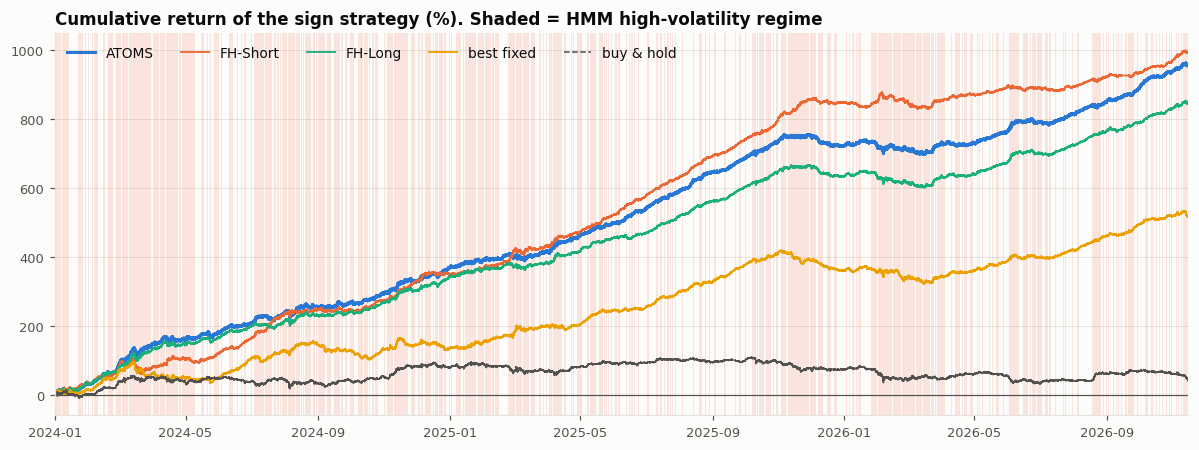

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.2))
shade_regimes(ax)
for name, col in strategies.items():
    pnl = evaluate.sign_strategy(rep[col], rep["ret_fwd"])["pnl"].cumsum()
    ax.plot(pnl.index, 100 * pnl, label=name, lw=2 if name == "ATOMS" else 1.2)
ax.plot(bh.index, 100 * bh.cumsum(), label="buy & hold", color=plotting.MUTED, lw=1, ls="--")
ax.axhline(0, color=plotting.MUTED, lw=0.8); ax.legend(ncol=5, loc="upper left"); ax.set_xlim(REPORT_FROM, rep.index.max())
ax.set_title("Cumulative return of the sign strategy (%). Shaded = HMM high-volatility regime"); plt.tight_layout(); plt.show()

### 6d. What ATOMS chose, and when

The first panel is the chart this method is for: which model family ATOMS picked each period (colour) and how long a training window (height). The second panel shows the average look-back ATOMS chose when comparing candidates: short when it judged old validation data stale, long when the market was steady. The third panel is **hindsight**: the candidate that actually did best on each period's test data, which no method could know in advance. If the hindsight winner keeps changing, no fixed choice could have been right, which is the paper's Figure 1 argument made on this data.

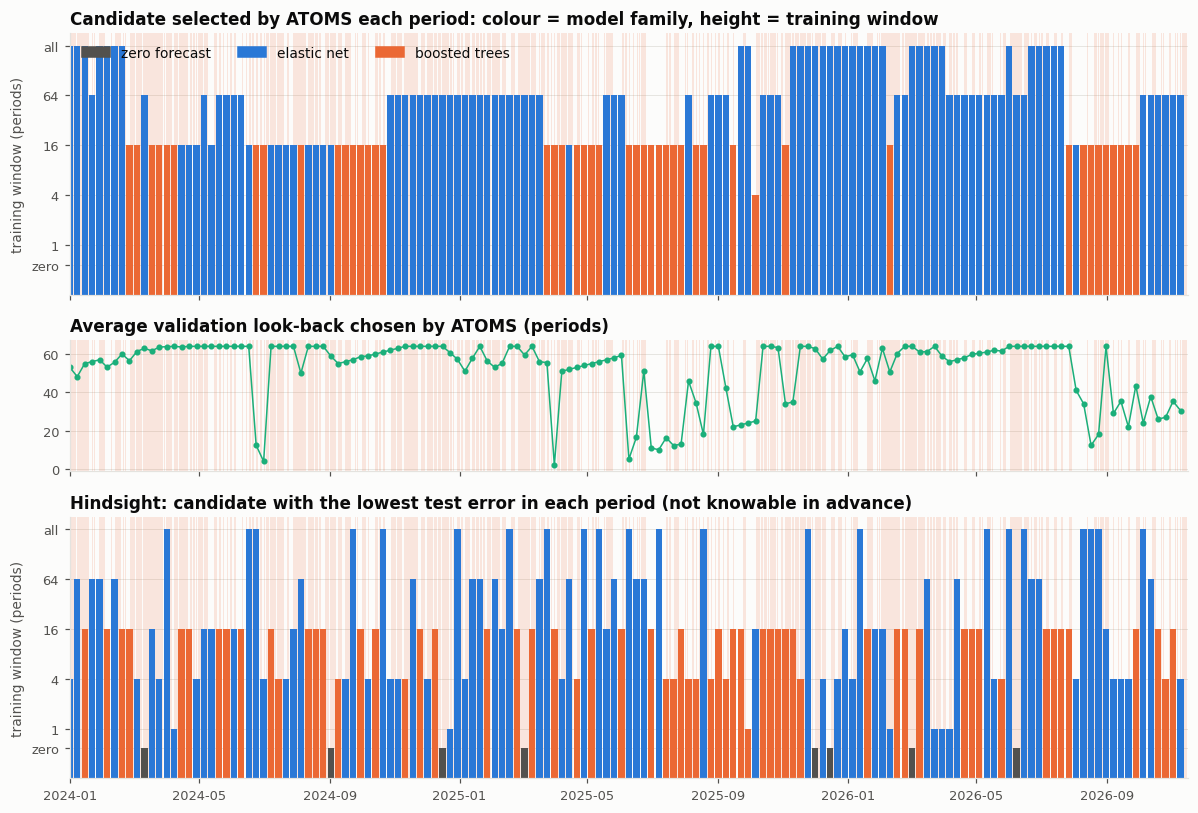

ATOMS picks by family:
atoms_kind
enet   69.3000
gbt    30.7000

ATOMS picked the hindsight-best candidate in 9% of periods; same family in 45%


col_0,boosted trees,elastic net
row_0,,
calm,39%,61%
stormy,25%,75%


In [17]:
s = sel.copy(); s.index = pd.PeriodIndex(s.index.astype(str), freq=PERIOD)
s = s[s.index.to_timestamp(how="end") >= REPORT_FROM.tz_localize(None)]
x = s.index.to_timestamp()
win_h = lambda w: {-1: 0.6, 1: 1, 4: 2, 16: 3, 64: 4, 0: 5}.get(int(w), 1)
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1, 2]})
for ax in axes: shade_regimes(ax)
axes[-1].set_xlim(REPORT_FROM.tz_localize(None), x.max() + pd.Timedelta(days=7))
axes[0].bar(x, [win_h(w) for w in s.atoms_window], width=6, color=[KIND_COLOR[k] for k in s.atoms_kind])
axes[0].set_yticks([0.6, 1, 2, 3, 4, 5]); axes[0].set_yticklabels(["zero", "1", "4", "16", "64", "all"]); axes[0].set_ylabel("training window (periods)")
axes[0].set_title("Candidate selected by ATOMS each period: colour = model family, height = training window")
axes[0].legend(handles=[Patch(color=v, label=KIND_NAME[k]) for k, v in KIND_COLOR.items()], ncol=3, loc="upper left")
axes[1].plot(x, s.atoms_lookback, color=plotting.AQUA, marker="o", ms=3, lw=1); axes[1].set_title("Average validation look-back chosen by ATOMS (periods)")
axes[2].bar(x, [win_h(w) for w in s.hindsight_window], width=6, color=[KIND_COLOR[k] for k in s.hindsight_kind])
axes[2].set_yticks([0.6, 1, 2, 3, 4, 5]); axes[2].set_yticklabels(["zero", "1", "4", "16", "64", "all"]); axes[2].set_ylabel("training window (periods)")
axes[2].set_title("Hindsight: candidate with the lowest test error in each period (not knowable in advance)")
plt.tight_layout(); plt.show()

print("ATOMS picks by family:"); print((100 * s.atoms_kind.value_counts(normalize=True)).round(1).to_string())
print("\nATOMS picked the hindsight-best candidate in", f"{100*(s.atoms == s.hindsight_best).mean():.0f}% of periods;",
      "same family in", f"{100*(s.atoms_kind == s.hindsight_kind).mean():.0f}%")
stormy_p = regime.groupby(regime.index.tz_convert(None).to_period(PERIOD)).mean().reindex(s.index).fillna(0) > 0.5
ct = pd.crosstab(np.where(stormy_p.values, "stormy", "calm"), s.atoms_kind.map(KIND_NAME).values, normalize="index") * 100
display(ct.round(1).style.format("{:.0f}%").set_caption("ATOMS's choice of family by regime (% of periods)"))

## 7. Summary

- **Non-stationarity:** prices have a unit root, while returns reject a unit root. Annualised 30-day realised volatility ranged from 22.9% to 77.1% (3.4x). All 11 non-time-of-day features flipped their feature-target correlation sign across months, and elastic-net coefficients varied materially month to month.
- **Regimes:** the HMM classified 52.2% of hours as high volatility. Expected state duration was about 12.3 hours in the calm state and 8.5 hours in the stormy state.
- **Accuracy:** ATOMS OOS R² was -0.0140%, versus +0.0074% for the best fixed candidate and -0.0119% for FH-Long. The Diebold-Mariano p-value versus the best fixed candidate was 0.052.
- **Strategy:** ATOMS achieved a daily-P&L Sharpe of 6.66 (95% block-bootstrap interval: [5.08, 8.09]) and maximum compounded-equity drawdown of -43.4%.
- **Selection:** ATOMS chose elastic net in 61.3% of calm weeks and 75.0% of stormy weeks. Its average validation look-back was 45.5 periods in calm weeks and 56.6 periods in stormy weeks.

**What would make this stronger with more time:** more seeds (the paper uses 20); a CSCV/PBO check across the settings tried. Notebook 04 adds richer features, regime features, PCA and position sizing on top of this baseline.